In [1]:
import pandas as pd
from google.colab import files
from io import BytesIO

# Selecionar o arquivo de produtividade do IBGE/PAM
arquivos = files.upload()

# Ler o arquivo CSV enviado
nome_arquivo = "produtividade_ibge_pam.csv"
df = pd.read_csv(BytesIO(arquivos[nome_arquivo]))

# Exibir as primeiras cinco observações
display(df.head())

# Verificar quantidade de linhas e colunas
print("Dimensões da base:", df.shape)

# Verificar nomes das colunas e tipos de dados
df.info()

Saving produtividade_ibge_pam.csv to produtividade_ibge_pam.csv


,municipio,ano,produto,area_colhida_ha,quantidade_produzida_t,rendimento_medio_kg_ha,valor_producao_mil_reais,preco_medio_produtor_r_kg
0,Casa Nova (BA),2010,Goiaba,98.0,1568.0,16000.0,1097.0,0.70
1,Casa Nova (BA),2011,Goiaba,96.0,1536.0,16000.0,1075.0,0.70
2,Casa Nova (BA),2012,Goiaba,96.0,1536.0,16000.0,983.0,0.64
3,Casa Nova (BA),2013,Goiaba,90.0,315.0,3500.0,270.0,0.86
4,Casa Nova (BA),2014,Goiaba,350.0,8400.0,24000.0,6510.0,0.78


Dimensões da base: (285, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 285 entries, 0 to 284
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   municipio                  285 non-null    object 
 1   ano                        285 non-null    int64  
 2   produto                    285 non-null    object 
 3   area_colhida_ha            285 non-null    float64
 4   quantidade_produzida_t     285 non-null    float64
 5   rendimento_medio_kg_ha     285 non-null    float64
 6   valor_producao_mil_reais   285 non-null    float64
 7   preco_medio_produtor_r_kg  285 non-null    float64
dtypes: float64(5), int64(1), object(2)
memory usage: 17.9+ KB


In [2]:

# Municípios presentes na base
print("=== MUNICÍPIOS ===")
print(df["municipio"].unique())

# Culturas presentes na base
print("\n=== CULTURAS ===")
print(df["produto"].unique())

# Período histórico
print("\n=== PERÍODO ===")
print("Ano inicial:", df["ano"].min())
print("Ano final:", df["ano"].max())

# Quantidade de registros por cultura
print("\n=== REGISTROS POR CULTURA ===")
print(df["produto"].value_counts())

# Quantidade de registros por município e cultura
print("\n=== REGISTROS POR MUNICÍPIO E CULTURA ===")
print(pd.crosstab(df["municipio"], df["produto"]))

# Verificar duplicatas na identificação de cada safra
print("\n=== DUPLICATAS POR MUNICÍPIO, CULTURA E ANO ===")
print(df.duplicated(subset=["municipio", "produto", "ano"]).sum())

=== MUNICÍPIOS ===
['Casa Nova (BA)' 'Curaçá (BA)' 'Juazeiro (BA)' 'Lagoa Grande (PE)'
 'Petrolina (PE)' 'Santa Maria da Boa Vista (PE)']

=== CULTURAS ===
['Goiaba' 'Manga' 'Uva']

=== PERÍODO ===
Ano inicial: 2010
Ano final: 2025

=== REGISTROS POR CULTURA ===
produto
Manga     96
Uva       96
Goiaba    93
Name: count, dtype: int64

=== REGISTROS POR MUNICÍPIO E CULTURA ===
produto                        Goiaba  Manga  Uva
municipio                                        
Casa Nova (BA)                     16     16   16
Curaçá (BA)                        16     16   16
Juazeiro (BA)                      16     16   16
Lagoa Grande (PE)                  13     16   16
Petrolina (PE)                     16     16   16
Santa Maria da Boa Vista (PE)      16     16   16

=== DUPLICATAS POR MUNICÍPIO, CULTURA E ANO ===
0


In [3]:
# Criar a produtividade em toneladas por hectare
df["produtividade_t_ha"] = df["rendimento_medio_kg_ha"] / 1000

# Estatísticas por cultura
print("=== ESTATÍSTICAS DE PRODUTIVIDADE (t/ha) ===")
display(
    df.groupby("produto")["produtividade_t_ha"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

# Verificar valores inválidos
print("\n=== VALORES INVÁLIDOS ===")
print("Produtividade negativa:",
      (df["produtividade_t_ha"] < 0).sum())

print("Produtividade igual a zero:",
      (df["produtividade_t_ha"] == 0).sum())

print("Área colhida negativa:",
      (df["area_colhida_ha"] < 0).sum())

print("Área colhida igual a zero:",
      (df["area_colhida_ha"] == 0).sum())

# Identificar os cinco maiores rendimentos
print("\n=== MAIORES PRODUTIVIDADES ===")
display(
    df.nlargest(5, "produtividade_t_ha")[
        ["municipio", "ano", "produto", "produtividade_t_ha"]
    ]
)

# Identificar os cinco menores rendimentos
print("\n=== MENORES PRODUTIVIDADES ===")
display(
    df.nsmallest(5, "produtividade_t_ha")[
        ["municipio", "ano", "produto", "produtividade_t_ha"]
    ]
)

=== ESTATÍSTICAS DE PRODUTIVIDADE (t/ha) ===


,count,mean,median,std,min,max
produto,,,,,,
Goiaba,93,27.33,30.00,10.14,3.50,48.00
Manga,96,26.02,25.00,7.54,13.72,51.13
Uva,96,35.24,32.58,9.66,22.00,62.80



=== VALORES INVÁLIDOS ===
Produtividade negativa: 0
Produtividade igual a zero: 0
Área colhida negativa: 0
Área colhida igual a zero: 0

=== MAIORES PRODUTIVIDADES ===


,municipio,ano,produto,produtividade_t_ha
243,Lagoa Grande (PE),2016,Uva,62.8
260,Petrolina (PE),2017,Uva,58.0
259,Petrolina (PE),2016,Uva,55.0
262,Petrolina (PE),2019,Uva,55.0
261,Petrolina (PE),2018,Uva,53.4



=== MENORES PRODUTIVIDADES ===


,municipio,ano,produto,produtividade_t_ha
3,Casa Nova (BA),2013,Goiaba,3.50
23,Curaçá (BA),2017,Goiaba,8.76
24,Curaçá (BA),2018,Goiaba,10.00
25,Curaçá (BA),2019,Goiaba,10.00
26,Curaçá (BA),2020,Goiaba,10.00


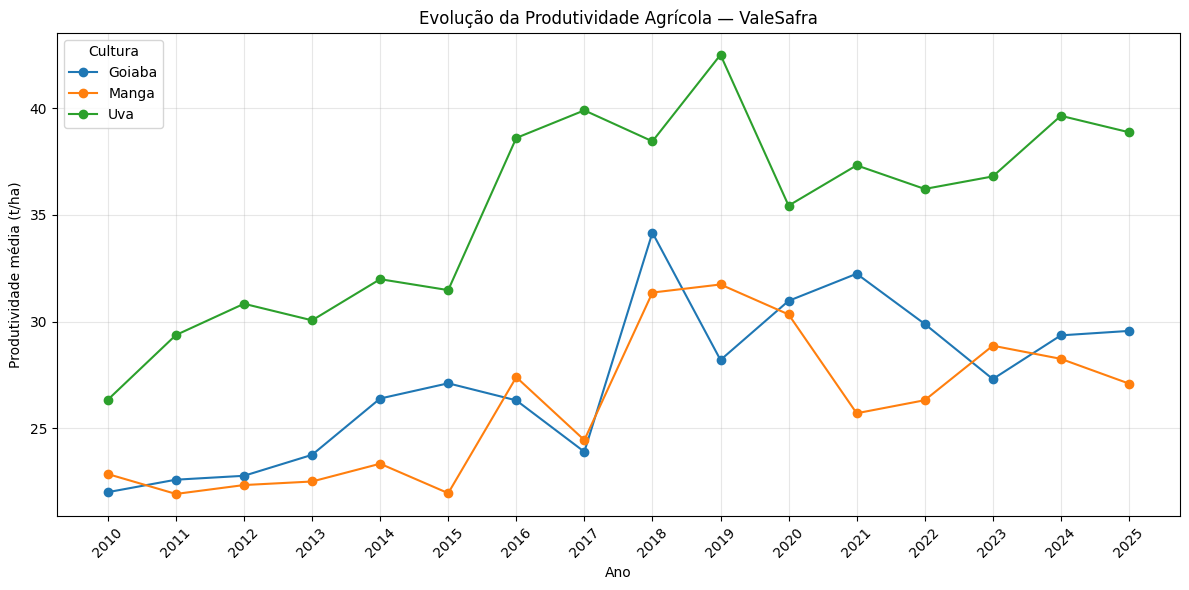

In [4]:
import matplotlib.pyplot as plt

# Média anual de produtividade por cultura
evolucao = (
    df.groupby(["ano", "produto"])["produtividade_t_ha"]
    .mean()
    .unstack()
)

# Gráfico da evolução histórica
plt.figure(figsize=(12, 6))

for cultura in evolucao.columns:
    plt.plot(
        evolucao.index,
        evolucao[cultura],
        marker="o",
        label=cultura
    )

plt.title("Evolução da Produtividade Agrícola — ValeSafra")
plt.xlabel("Ano")
plt.ylabel("Produtividade média (t/ha)")
plt.xticks(evolucao.index, rotation=45)
plt.legend(title="Cultura")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
# Ordenar os dados por município, cultura e ano
df = df.sort_values(
    ["municipio", "produto", "ano"]
).copy()

# Criar variáveis históricas
grupos = df.groupby(["municipio", "produto"])

df["produtividade_ano_anterior"] = grupos[
    "produtividade_t_ha"
].shift(1)

df["produtividade_2_anos_antes"] = grupos[
    "produtividade_t_ha"
].shift(2)

# Conferir se os registros anteriores correspondem
# realmente a anos consecutivos
ano_anterior = grupos["ano"].shift(1)
dois_anos_antes = grupos["ano"].shift(2)

df.loc[
    ano_anterior != df["ano"] - 1,
    "produtividade_ano_anterior"
] = float("nan")

df.loc[
    dois_anos_antes != df["ano"] - 2,
    "produtividade_2_anos_antes"
] = float("nan")

# Verificar a quantidade de registros utilizáveis
variaveis_historicas = [
    "produtividade_ano_anterior",
    "produtividade_2_anos_antes"
]

df_modelo = df.dropna(
    subset=variaveis_historicas
).copy()

print("Registros originais:", len(df))
print("Registros utilizáveis:", len(df_modelo))
print("Registros sem histórico completo:",
      len(df) - len(df_modelo))

# Visualizar exemplos
display(
    df_modelo[
        [
            "municipio",
            "produto",
            "ano",
            "produtividade_ano_anterior",
            "produtividade_2_anos_antes",
            "produtividade_t_ha"
        ]
    ].head(10)
)

Registros originais: 285
Registros utilizáveis: 247
Registros sem histórico completo: 38


,municipio,produto,ano,produtividade_ano_anterior,produtividade_2_anos_antes,produtividade_t_ha
2,Casa Nova (BA),Goiaba,2012,16.000,16.000,16.000
3,Casa Nova (BA),Goiaba,2013,16.000,16.000,3.500
4,Casa Nova (BA),Goiaba,2014,3.500,16.000,24.000
5,Casa Nova (BA),Goiaba,2015,24.000,3.500,25.000
6,Casa Nova (BA),Goiaba,2016,25.000,24.000,21.000
7,Casa Nova (BA),Goiaba,2017,21.000,25.000,30.588
8,Casa Nova (BA),Goiaba,2018,30.588,21.000,30.000
9,Casa Nova (BA),Goiaba,2019,30.000,30.588,28.320
10,Casa Nova (BA),Goiaba,2020,28.320,30.000,24.864
11,Casa Nova (BA),Goiaba,2021,24.864,28.320,25.619


In [6]:
# Separação cronológica
treino = df_modelo[df_modelo["ano"] <= 2022].copy()
teste = df_modelo[df_modelo["ano"] >= 2023].copy()

# Variáveis utilizadas pelo modelo
variaveis = [
    "municipio",
    "produto",
    "ano",
    "produtividade_ano_anterior",
    "produtividade_2_anos_antes"
]

# Entradas (X) e variável-alvo (y)
X_treino = treino[variaveis]
y_treino = treino["produtividade_t_ha"]

X_teste = teste[variaveis]
y_teste = teste["produtividade_t_ha"]

# Resumo da divisão
print("=== TREINAMENTO ===")
print("Observações:", len(treino))
print("Período:", treino["ano"].min(), "a", treino["ano"].max())

print("\n=== TESTE ===")
print("Observações:", len(teste))
print("Período:", teste["ano"].min(), "a", teste["ano"].max())

print("\n=== DISTRIBUIÇÃO POR CULTURA ===")
print("Treinamento:")
print(treino["produto"].value_counts())

print("\nTeste:")
print(teste["produto"].value_counts())

=== TREINAMENTO ===
Observações: 193
Período: 2012 a 2022

=== TESTE ===
Observações: 54
Período: 2023 a 2025

=== DISTRIBUIÇÃO POR CULTURA ===
Treinamento:
produto
Manga     66
Uva       66
Goiaba    61
Name: count, dtype: int64

Teste:
produto
Goiaba    18
Manga     18
Uva       18
Name: count, dtype: int64


In [7]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline: produtividade do ano anterior
previsoes_baseline = X_teste[
    "produtividade_ano_anterior"
].to_numpy()

# Valores reais
valores_reais = y_teste.to_numpy()

# Calcular métricas
mae_baseline = mean_absolute_error(
    valores_reais,
    previsoes_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(
        valores_reais,
        previsoes_baseline
    )
)

print("=== BASELINE: ANO ANTERIOR ===")
print(f"MAE: {mae_baseline:.3f} t/ha")
print(f"RMSE: {rmse_baseline:.3f} t/ha")

# Avaliação separada por cultura
resultados_baseline = teste[
    ["municipio", "produto", "ano", "produtividade_t_ha"]
].copy()

resultados_baseline["previsao"] = previsoes_baseline

resultados_baseline["erro_absoluto"] = abs(
    resultados_baseline["produtividade_t_ha"]
    - resultados_baseline["previsao"]
)

print("\n=== ERRO MÉDIO POR CULTURA ===")

display(
    resultados_baseline.groupby("produto")[
        "erro_absoluto"
    ].mean().round(3)
)

=== BASELINE: ANO ANTERIOR ===
MAE: 3.048 t/ha
RMSE: 4.840 t/ha

=== ERRO MÉDIO POR CULTURA ===


,erro_absoluto
produto,
Goiaba,2.970
Manga,3.625
Uva,2.548


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Variáveis categóricas e numéricas
categoricas = ["municipio", "produto"]

numericas = [
    "ano",
    "produtividade_ano_anterior",
    "produtividade_2_anos_antes"
]

# Preparação das variáveis
preprocessador = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            categoricas
        ),
        (
            "numericas",
            StandardScaler(),
            numericas
        )
    ]
)

# Pipeline completo: preparação + modelo
modelo_ridge = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        ("regressao", Ridge(alpha=10.0))
    ]
)

# Treinar apenas com os anos de treinamento
modelo_ridge.fit(X_treino, y_treino)

# Fazer previsões para 2023–2025
previsoes_ridge = modelo_ridge.predict(X_teste)

# Avaliar desempenho
mae_ridge = mean_absolute_error(
    y_teste, previsoes_ridge
)

rmse_ridge = mean_squared_error(
    y_teste, previsoes_ridge
) ** 0.5

print("=== MODELO RIDGE REGRESSION ===")
print(f"MAE: {mae_ridge:.3f} t/ha")
print(f"RMSE: {rmse_ridge:.3f} t/ha")

print("\n=== COMPARAÇÃO COM BASELINE ===")
print(f"Baseline MAE: {mae_baseline:.3f}")
print(f"Ridge MAE:    {mae_ridge:.3f}")

melhoria = (
    (mae_baseline - mae_ridge)
    / mae_baseline
) * 100

print(f"Melhoria no MAE: {melhoria:.2f}%")

# Erro médio por cultura
resultados_ridge = teste[
    ["municipio", "produto", "ano", "produtividade_t_ha"]
].copy()

resultados_ridge["previsao"] = previsoes_ridge

resultados_ridge["erro_absoluto"] = abs(
    resultados_ridge["produtividade_t_ha"]
    - resultados_ridge["previsao"]
)

print("\n=== MAE POR CULTURA ===")

display(
    resultados_ridge.groupby("produto")[
        "erro_absoluto"
    ].mean().round(3)
)

=== MODELO RIDGE REGRESSION ===
MAE: 3.759 t/ha
RMSE: 4.818 t/ha

=== COMPARAÇÃO COM BASELINE ===
Baseline MAE: 3.048
Ridge MAE:    3.759
Melhoria no MAE: -23.33%

=== MAE POR CULTURA ===


,erro_absoluto
produto,
Goiaba,4.436
Manga,4.444
Uva,2.398


In [9]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Criar o modelo Random Forest
modelo_rf = Pipeline(
    steps=[
        ("preprocessamento", preprocessador),
        (
            "regressao",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=5,
                min_samples_leaf=3,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

# Treinar com os dados de 2012 a 2022
modelo_rf.fit(X_treino, y_treino)

# Prever os anos de 2023 a 2025
previsoes_rf = modelo_rf.predict(X_teste)

# Calcular métricas
mae_rf = mean_absolute_error(
    y_teste,
    previsoes_rf
)

rmse_rf = mean_squared_error(
    y_teste,
    previsoes_rf
) ** 0.5

print("=== RANDOM FOREST REGRESSOR ===")
print(f"MAE: {mae_rf:.3f} t/ha")
print(f"RMSE: {rmse_rf:.3f} t/ha")

# Comparar os três métodos
print("\n=== COMPARAÇÃO GERAL ===")

comparacao = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE (t/ha)": [
        mae_baseline,
        mae_ridge,
        mae_rf
    ],
    "RMSE (t/ha)": [
        rmse_baseline,
        rmse_ridge,
        rmse_rf
    ]
})

display(comparacao.round(3))

# Erro por cultura
resultados_rf = teste[
    ["municipio", "produto", "ano", "produtividade_t_ha"]
].copy()

resultados_rf["previsao"] = previsoes_rf

resultados_rf["erro_absoluto"] = abs(
    resultados_rf["produtividade_t_ha"]
    - resultados_rf["previsao"]
)

print("\n=== MAE POR CULTURA ===")

display(
    resultados_rf.groupby("produto")[
        "erro_absoluto"
    ].mean().round(3)
)

=== RANDOM FOREST REGRESSOR ===
MAE: 3.931 t/ha
RMSE: 5.442 t/ha

=== COMPARAÇÃO GERAL ===


,Modelo,MAE (t/ha),RMSE (t/ha)
0,Baseline,3.048,4.840
1,Ridge Regression,3.759,4.818
2,Random Forest,3.931,5.442



=== MAE POR CULTURA ===


,erro_absoluto
produto,
Goiaba,4.949
Manga,4.003
Uva,2.841


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Previsões no conjunto de treinamento
previsoes_rf_treino = modelo_rf.predict(X_treino)

# Métricas do treinamento
mae_rf_treino = mean_absolute_error(
    y_treino,
    previsoes_rf_treino
)

rmse_rf_treino = mean_squared_error(
    y_treino,
    previsoes_rf_treino
) ** 0.5

# Comparação entre treinamento e teste
print("=== RANDOM FOREST: TREINO VS TESTE ===")

print(f"MAE Treinamento: {mae_rf_treino:.3f} t/ha")
print(f"MAE Teste:       {mae_rf:.3f} t/ha")

print(f"\nRMSE Treinamento: {rmse_rf_treino:.3f} t/ha")
print(f"RMSE Teste:       {rmse_rf:.3f} t/ha")

# Diferença entre os erros
diferenca_mae = mae_rf - mae_rf_treino

print(f"\nDiferença no MAE: {diferenca_mae:.3f} t/ha")

=== RANDOM FOREST: TREINO VS TESTE ===
MAE Treinamento: 3.223 t/ha
MAE Teste:       3.931 t/ha

RMSE Treinamento: 4.739 t/ha
RMSE Teste:       5.442 t/ha

Diferença no MAE: 0.708 t/ha


In [11]:
# Definir os anos de validação temporal
anos_validacao = [2018, 2019, 2020, 2021, 2022]

# Preparar os períodos de treinamento e validação
for ano_validacao in anos_validacao:

    dados_treino = treino[
        treino["ano"] < ano_validacao
    ]

    dados_validacao = treino[
        treino["ano"] == ano_validacao
    ]

    print(f"\n=== VALIDAÇÃO DO ANO {ano_validacao} ===")

    print(
        "Treinamento:",
        dados_treino["ano"].min(),
        "a",
        dados_treino["ano"].max()
    )

    print(
        "Observações de treinamento:",
        len(dados_treino)
    )

    print(
        "Observações de validação:",
        len(dados_validacao)
    )


=== VALIDAÇÃO DO ANO 2018 ===
Treinamento: 2012 a 2017
Observações de treinamento: 105
Observações de validação: 17

=== VALIDAÇÃO DO ANO 2019 ===
Treinamento: 2012 a 2018
Observações de treinamento: 122
Observações de validação: 17

=== VALIDAÇÃO DO ANO 2020 ===
Treinamento: 2012 a 2019
Observações de treinamento: 139
Observações de validação: 18

=== VALIDAÇÃO DO ANO 2021 ===
Treinamento: 2012 a 2020
Observações de treinamento: 157
Observações de validação: 18

=== VALIDAÇÃO DO ANO 2022 ===
Treinamento: 2012 a 2021
Observações de treinamento: 175
Observações de validação: 18


In [12]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd

resultados_validacao = []

for ano_validacao in anos_validacao:

    # Separação cronológica
    dados_treino = treino[
        treino["ano"] < ano_validacao
    ]

    dados_validacao = treino[
        treino["ano"] == ano_validacao
    ]

    X_train = dados_treino[variaveis]
    y_train = dados_treino["produtividade_t_ha"]

    X_val = dados_validacao[variaveis]
    y_val = dados_validacao["produtividade_t_ha"]

    # 1. Baseline
    previsao_baseline = dados_validacao[
        "produtividade_ano_anterior"
    ]

    mae_base = mean_absolute_error(
        y_val, previsao_baseline
    )

    # 2. Ridge Regression
    ridge = clone(modelo_ridge)
    ridge.fit(X_train, y_train)

    previsao_ridge = ridge.predict(X_val)

    mae_r = mean_absolute_error(
        y_val, previsao_ridge
    )

    # 3. Random Forest
    rf = clone(modelo_rf)
    rf.fit(X_train, y_train)

    previsao_rf = rf.predict(X_val)

    mae_f = mean_absolute_error(
        y_val, previsao_rf
    )

    resultados_validacao.append({
        "Ano": ano_validacao,
        "Baseline": mae_base,
        "Ridge": mae_r,
        "Random Forest": mae_f
    })

# Organizar os resultados
df_validacao = pd.DataFrame(resultados_validacao)

print("=== MAE POR ANO DE VALIDAÇÃO (t/ha) ===")
display(df_validacao.round(3))

print("\n=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===")
display(
    df_validacao[
        ["Baseline", "Ridge", "Random Forest"]
    ].mean().sort_values().round(3)
)

=== MAE POR ANO DE VALIDAÇÃO (t/ha) ===


,Ano,Baseline,Ridge,Random Forest
0,2018,8.373,8.952,9.300
1,2019,4.740,4.256,4.563
2,2020,4.336,5.428,5.965
3,2021,4.888,4.858,4.965
4,2022,2.206,3.110,2.141



=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===


,0
Baseline,4.909
Ridge,5.321
Random Forest,5.387


In [13]:
# Selecionar os dados de 2018
dados_2018 = treino[
    treino["ano"] == 2018
].copy()

# Calcular a previsão do baseline
dados_2018["previsao_baseline"] = (
    dados_2018["produtividade_ano_anterior"]
)

# Calcular o erro absoluto
dados_2018["erro_absoluto"] = abs(
    dados_2018["produtividade_t_ha"]
    - dados_2018["previsao_baseline"]
)

# Selecionar as informações importantes
analise_2018 = dados_2018[
    [
        "municipio",
        "produto",
        "produtividade_ano_anterior",
        "produtividade_t_ha",
        "erro_absoluto"
    ]
].sort_values(
    "erro_absoluto",
    ascending=False
)

print("=== MAIORES ERROS DO BASELINE EM 2018 ===")
display(analise_2018.round(3))

print("\n=== MAE POR CULTURA EM 2018 ===")
display(
    dados_2018.groupby("produto")[
        "erro_absoluto"
    ].mean().round(3)
)

=== MAIORES ERROS DO BASELINE EM 2018 ===


,municipio,produto,produtividade_ano_anterior,produtividade_t_ha,erro_absoluto
165,Petrolina (PE),Manga,22.000,45.000,23.000
181,Santa Maria da Boa Vista (PE),Manga,30.000,50.000,20.000
85,Santa Maria da Boa Vista (PE),Goiaba,30.000,48.000,18.000
40,Juazeiro (BA),Goiaba,15.117,32.000,16.883
149,Lagoa Grande (PE),Manga,20.000,35.000,15.000
101,Casa Nova (BA),Manga,37.500,25.000,12.500
245,Lagoa Grande (PE),Uva,50.000,39.677,10.323
69,Petrolina (PE),Goiaba,35.000,45.000,10.000
261,Petrolina (PE),Uva,58.000,53.400,4.600
229,Juazeiro (BA),Uva,27.826,30.455,2.629



=== MAE POR CULTURA EM 2018 ===


,erro_absoluto
produto,
Goiaba,9.342
Manga,12.417
Uva,3.522


In [14]:
# Selecionar os cinco maiores erros de 2018
maiores_erros = analise_2018.head(5)[
    ["municipio", "produto"]
]

# Buscar os dados de 2017 e 2018
dados_comparacao = df[
    df["ano"].isin([2017, 2018])
].merge(
    maiores_erros,
    on=["municipio", "produto"],
    how="inner"
)

# Selecionar as colunas importantes
dados_comparacao = dados_comparacao[
    [
        "municipio",
        "produto",
        "ano",
        "area_colhida_ha",
        "quantidade_produzida_t",
        "produtividade_t_ha"
    ]
]

# Organizar os resultados
dados_comparacao = dados_comparacao.sort_values(
    ["municipio", "produto", "ano"]
)

print("=== COMPARAÇÃO ENTRE 2017 E 2018 ===")
display(dados_comparacao.round(3))

=== COMPARAÇÃO ENTRE 2017 E 2018 ===


,municipio,produto,ano,area_colhida_ha,quantidade_produzida_t,produtividade_t_ha
0,Juazeiro (BA),Goiaba,2017,360.0,5442.0,15.117
1,Juazeiro (BA),Goiaba,2018,750.0,24000.0,32.000
2,Lagoa Grande (PE),Manga,2017,230.0,4140.0,20.000
3,Lagoa Grande (PE),Manga,2018,400.0,14000.0,35.000
4,Petrolina (PE),Manga,2017,7880.0,173360.0,22.000
5,Petrolina (PE),Manga,2018,8150.0,366750.0,45.000
6,Santa Maria da Boa Vista (PE),Goiaba,2017,1250.0,37500.0,30.000
7,Santa Maria da Boa Vista (PE),Goiaba,2018,1700.0,81600.0,48.000
8,Santa Maria da Boa Vista (PE),Manga,2017,1400.0,42000.0,30.000
9,Santa Maria da Boa Vista (PE),Manga,2018,1170.0,58500.0,50.000


In [15]:
# Organizar os dados cronologicamente
df = df.sort_values(
    ["municipio", "produto", "ano"]
).copy()

grupos = df.groupby(["municipio", "produto"])

# Criar variáveis históricas de área e produção
for coluna in [
    "area_colhida_ha",
    "quantidade_produzida_t"
]:
    for atraso in [1, 2]:

        nome_novo = f"{coluna}_lag{atraso}"

        df[nome_novo] = grupos[coluna].shift(atraso)

        # Verificar continuidade dos anos
        ano_passado = grupos["ano"].shift(atraso)

        df.loc[
            ano_passado != df["ano"] - atraso,
            nome_novo
        ] = float("nan")

# Definir as novas variáveis
novas_variaveis = [
    "area_colhida_ha_lag1",
    "area_colhida_ha_lag2",
    "quantidade_produzida_t_lag1",
    "quantidade_produzida_t_lag2"
]

# Preparar a base ampliada
df_modelo_ampliado = df.dropna(
    subset=variaveis_historicas + novas_variaveis
).copy()

print("=== BASE AMPLIADA ===")

print(
    "Observações disponíveis:",
    len(df_modelo_ampliado)
)

print(
    "\nValores ausentes nas novas variáveis:"
)

print(
    df_modelo_ampliado[
        novas_variaveis
    ].isna().sum()
)

print("\n=== EXEMPLO DOS DADOS ===")

display(
    df_modelo_ampliado[
        [
            "municipio",
            "produto",
            "ano",
            "produtividade_t_ha"
        ] + novas_variaveis
    ].head(10)
)

=== BASE AMPLIADA ===
Observações disponíveis: 247

Valores ausentes nas novas variáveis:
area_colhida_ha_lag1           0
area_colhida_ha_lag2           0
quantidade_produzida_t_lag1    0
quantidade_produzida_t_lag2    0
dtype: int64

=== EXEMPLO DOS DADOS ===


,municipio,produto,ano,produtividade_t_ha,area_colhida_ha_lag1,area_colhida_ha_lag2,quantidade_produzida_t_lag1,quantidade_produzida_t_lag2
2,Casa Nova (BA),Goiaba,2012,16.000,96.0,98.0,1536.0,1568.0
3,Casa Nova (BA),Goiaba,2013,3.500,96.0,96.0,1536.0,1536.0
4,Casa Nova (BA),Goiaba,2014,24.000,90.0,96.0,315.0,1536.0
5,Casa Nova (BA),Goiaba,2015,25.000,350.0,90.0,8400.0,315.0
6,Casa Nova (BA),Goiaba,2016,21.000,400.0,350.0,10000.0,8400.0
7,Casa Nova (BA),Goiaba,2017,30.588,650.0,400.0,13650.0,10000.0
8,Casa Nova (BA),Goiaba,2018,30.000,850.0,650.0,26000.0,13650.0
9,Casa Nova (BA),Goiaba,2019,28.320,900.0,850.0,27000.0,26000.0
10,Casa Nova (BA),Goiaba,2020,24.864,1250.0,900.0,35400.0,27000.0
11,Casa Nova (BA),Goiaba,2021,25.619,1180.0,1250.0,29340.0,35400.0


In [16]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Variáveis originais + novas variáveis históricas
variaveis_ampliadas = variaveis + novas_variaveis

# Separar variáveis por tipo
categoricas_ampliadas = ["municipio", "produto"]

numericas_ampliadas = [
    "ano",
    "produtividade_ano_anterior",
    "produtividade_2_anos_antes"
] + novas_variaveis

# Preparação dos dados
preprocessador_ampliado = ColumnTransformer(
    transformers=[
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            categoricas_ampliadas
        ),
        (
            "numericas",
            StandardScaler(),
            numericas_ampliadas
        )
    ]
)

# Modelos com as variáveis ampliadas
ridge_ampliado = Pipeline([
    ("preprocessamento", preprocessador_ampliado),
    ("regressao", Ridge(alpha=10.0))
])

rf_ampliado = Pipeline([
    ("preprocessamento", preprocessador_ampliado),
    ("regressao", RandomForestRegressor(
        n_estimators=200,
        max_depth=5,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

# Separar apenas os anos destinados ao treinamento
treino_ampliado = df_modelo_ampliado[
    df_modelo_ampliado["ano"] <= 2022
].copy()

resultados_ampliados = []

# Validação temporal
for ano_validacao in anos_validacao:

    dados_treino = treino_ampliado[
        treino_ampliado["ano"] < ano_validacao
    ]

    dados_validacao = treino_ampliado[
        treino_ampliado["ano"] == ano_validacao
    ]

    X_train = dados_treino[variaveis_ampliadas]
    y_train = dados_treino["produtividade_t_ha"]

    X_val = dados_validacao[variaveis_ampliadas]
    y_val = dados_validacao["produtividade_t_ha"]

    # Ridge ampliado
    ridge = clone(ridge_ampliado)
    ridge.fit(X_train, y_train)

    mae_ridge_amp = mean_absolute_error(
        y_val,
        ridge.predict(X_val)
    )

    # Random Forest ampliado
    rf = clone(rf_ampliado)
    rf.fit(X_train, y_train)

    mae_rf_amp = mean_absolute_error(
        y_val,
        rf.predict(X_val)
    )

    resultados_ampliados.append({
        "Ano": ano_validacao,
        "Ridge Ampliado": mae_ridge_amp,
        "RF Ampliado": mae_rf_amp
    })

# Comparar com os resultados anteriores
df_ampliado = pd.DataFrame(resultados_ampliados)

comparacao_ampliada = df_validacao.merge(
    df_ampliado,
    on="Ano"
)

print("=== COMPARAÇÃO POR ANO (MAE EM t/ha) ===")
display(comparacao_ampliada.round(3))

print("\n=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===")
display(
    comparacao_ampliada.drop(
        columns="Ano"
    ).mean().sort_values().round(3)
)

=== COMPARAÇÃO POR ANO (MAE EM t/ha) ===


,Ano,Baseline,Ridge,Random Forest,Ridge Ampliado,RF Ampliado
0,2018,8.373,8.952,9.300,9.749,9.700
1,2019,4.740,4.256,4.563,4.134,4.074
2,2020,4.336,5.428,5.965,5.750,5.892
3,2021,4.888,4.858,4.965,4.820,5.317
4,2022,2.206,3.110,2.141,2.999,2.367



=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===


,0
Baseline,4.909
Ridge,5.321
Random Forest,5.387
RF Ampliado,5.470
Ridge Ampliado,5.490


In [17]:
from sklearn.metrics import mean_absolute_error
import pandas as pd

resultados_baselines = []

for ano_validacao in anos_validacao:

    dados_val = treino[
        treino["ano"] == ano_validacao
    ].copy()

    y_real = dados_val["produtividade_t_ha"]

    ano_1 = dados_val[
        "produtividade_ano_anterior"
    ]

    ano_2 = dados_val[
        "produtividade_2_anos_antes"
    ]

    # Método 1: repetir o ano anterior
    previsao_persistencia = ano_1

    # Método 2: média dos últimos dois anos
    previsao_media = (ano_1 + ano_2) / 2

    # Método 3: média ponderada
    # 70% para o ano anterior e 30% para dois anos antes
    previsao_ponderada = (
        0.7 * ano_1 + 0.3 * ano_2
    )

    resultados_baselines.append({
        "Ano": ano_validacao,

        "Persistência": mean_absolute_error(
            y_real, previsao_persistencia
        ),

        "Média 2 anos": mean_absolute_error(
            y_real, previsao_media
        ),

        "Média ponderada": mean_absolute_error(
            y_real, previsao_ponderada
        )
    })

df_baselines = pd.DataFrame(resultados_baselines)

print("=== MAE POR ANO (t/ha) ===")
display(df_baselines.round(3))

print("\n=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===")
display(
    df_baselines.drop(
        columns="Ano"
    ).mean().sort_values().round(3)
)

=== MAE POR ANO (t/ha) ===


,Ano,Persistência,Média 2 anos,Média ponderada
0,2018,8.373,10.097,9.320
1,2019,4.740,4.532,4.368
2,2020,4.336,4.031,4.066
3,2021,4.888,4.280,4.407
4,2022,2.206,2.667,2.458



=== MAE MÉDIO NAS CINCO VALIDAÇÕES ===


,0
Persistência,4.909
Média ponderada,4.924
Média 2 anos,5.122


In [18]:
# Selecionar os anos de validação
dados_culturas = treino[
    treino["ano"].isin(anos_validacao)
].copy()

# Valores reais
dados_culturas["real"] = (
    dados_culturas["produtividade_t_ha"]
)

# Persistência
dados_culturas["persistencia"] = (
    dados_culturas["produtividade_ano_anterior"]
)

# Média simples de dois anos
dados_culturas["media_2_anos"] = (
    dados_culturas["produtividade_ano_anterior"]
    + dados_culturas["produtividade_2_anos_antes"]
) / 2

# Média ponderada
dados_culturas["media_ponderada"] = (
    0.7 * dados_culturas["produtividade_ano_anterior"]
    + 0.3 * dados_culturas["produtividade_2_anos_antes"]
)

# Calcular erros absolutos
metodos = [
    "persistencia",
    "media_2_anos",
    "media_ponderada"
]

for metodo in metodos:
    dados_culturas[f"erro_{metodo}"] = abs(
        dados_culturas["real"]
        - dados_culturas[metodo]
    )

# Calcular MAE por cultura
comparacao_culturas = dados_culturas.groupby(
    "produto"
)[
    [f"erro_{metodo}" for metodo in metodos]
].mean()

comparacao_culturas.columns = [
    "Persistência",
    "Média 2 anos",
    "Média ponderada"
]

print("=== MAE POR CULTURA (2018–2022) ===")
display(comparacao_culturas.round(3))

print("\n=== MELHOR MÉTODO POR CULTURA ===")
display(comparacao_culturas.idxmin(axis=1))

=== MAE POR CULTURA (2018–2022) ===


,Persistência,Média 2 anos,Média ponderada
produto,,,
Goiaba,5.269,4.509,4.685
Manga,5.090,6.534,5.815
Uva,4.281,4.135,4.128



=== MELHOR MÉTODO POR CULTURA ===


,0
produto,
Goiaba,Média 2 anos
Manga,Persistência
Uva,Média ponderada


In [19]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Selecionar os dados de teste (2023–2025)
teste_hibrido = teste.copy()

# Valores históricos
ano_1 = teste_hibrido["produtividade_ano_anterior"]
ano_2 = teste_hibrido["produtividade_2_anos_antes"]

# Previsão por persistência
teste_hibrido["previsao_persistencia"] = ano_1

# Previsão híbrida, conforme a cultura
teste_hibrido["previsao_hibrida"] = np.select(
    [
        teste_hibrido["produto"] == "Goiaba",
        teste_hibrido["produto"] == "Manga",
        teste_hibrido["produto"] == "Uva"
    ],
    [
        (ano_1 + ano_2) / 2,
        ano_1,
        0.7 * ano_1 + 0.3 * ano_2
    ],
    default=np.nan
)

# Valores reais
y_real = teste_hibrido["produtividade_t_ha"]

# Calcular métricas
resultados = []

for metodo in [
    "previsao_persistencia",
    "previsao_hibrida"
]:
    previsoes = teste_hibrido[metodo]

    resultados.append({
        "Método": metodo,
        "MAE": mean_absolute_error(y_real, previsoes),
        "RMSE": np.sqrt(
            mean_squared_error(y_real, previsoes)
        )
    })

print("=== COMPARAÇÃO NO TESTE (2023–2025) ===")
display(pd.DataFrame(resultados).round(3))

# Comparação por cultura
for metodo in [
    "previsao_persistencia",
    "previsao_hibrida"
]:
    teste_hibrido[f"erro_{metodo}"] = abs(
        y_real - teste_hibrido[metodo]
    )

print("\n=== MAE POR CULTURA ===")
display(
    teste_hibrido.groupby("produto")[
        [
            "erro_previsao_persistencia",
            "erro_previsao_hibrida"
        ]
    ].mean().round(3)
)

=== COMPARAÇÃO NO TESTE (2023–2025) ===


,Método,MAE,RMSE
0,previsao_persistencia,3.048,4.840
1,previsao_hibrida,3.421,5.294



=== MAE POR CULTURA ===


,erro_previsao_persistencia,erro_previsao_hibrida
produto,,
Goiaba,2.970,4.234
Manga,3.625,3.625
Uva,2.548,2.403


In [20]:
# Calcular a produtividade a partir da produção e área
df["produtividade_calculada"] = (
    df["quantidade_produzida_t"]
    / df["area_colhida_ha"]
)

# Diferença em relação à produtividade informada
df["diferenca_produtividade"] = abs(
    df["produtividade_calculada"]
    - df["produtividade_t_ha"]
)

print("=== CONSISTÊNCIA DOS DADOS ===")

print("Total de registros:", len(df))

print(
    "Maior diferença encontrada:",
    round(df["diferenca_produtividade"].max(), 6)
)

print(
    "Registros com diferença acima de 0,01 t/ha:",
    (df["diferenca_produtividade"] > 0.01).sum()
)

print("\n=== MAIORES DIFERENÇAS ===")

display(
    df[
        [
            "municipio",
            "produto",
            "ano",
            "produtividade_t_ha",
            "produtividade_calculada",
            "diferenca_produtividade"
        ]
    ].sort_values(
        "diferenca_produtividade",
        ascending=False
    ).head(10).round(4)
)

=== CONSISTÊNCIA DOS DADOS ===
Total de registros: 285
Maior diferença encontrada: 23.068182
Registros com diferença acima de 0,01 t/ha: 16

=== MAIORES DIFERENÇAS ===


,municipio,produto,ano,produtividade_t_ha,produtividade_calculada,diferenca_produtividade
173,Santa Maria da Boa Vista (PE),Manga,2010,25.000,1.9318,23.0682
77,Santa Maria da Boa Vista (PE),Goiaba,2010,30.000,7.5000,22.5000
247,Lagoa Grande (PE),Uva,2020,42.710,29.8968,12.8132
53,Lagoa Grande (PE),Goiaba,2018,40.000,28.0000,12.0000
249,Lagoa Grande (PE),Uva,2022,47.000,39.3784,7.6216
265,Petrolina (PE),Uva,2022,43.000,36.6667,6.3333
147,Lagoa Grande (PE),Manga,2016,20.000,14.0488,5.9512
171,Petrolina (PE),Manga,2024,30.000,25.6364,4.3636
281,Santa Maria da Boa Vista (PE),Uva,2022,42.000,39.2000,2.8000
109,Curaçá (BA),Manga,2010,26.648,24.0000,2.6480


In [21]:
# Selecionar os registros com divergência relevante
inconsistencias = df[
    df["diferenca_produtividade"] > 0.01
].copy()

# Organizar por ano, município e cultura
inconsistencias = inconsistencias.sort_values(
    ["ano", "municipio", "produto"]
)

print("=== TODOS OS REGISTROS DIVERGENTES ===")

display(
    inconsistencias[
        [
            "municipio",
            "produto",
            "ano",
            "area_colhida_ha",
            "quantidade_produzida_t",
            "produtividade_t_ha",
            "produtividade_calculada",
            "diferenca_produtividade"
        ]
    ].round(3)
)

print("\n=== INCONSISTÊNCIAS POR ANO ===")

display(
    inconsistencias.groupby("ano").size()
)

print("\n=== INCONSISTÊNCIAS POR CULTURA ===")

display(
    inconsistencias.groupby("produto").size()
)

=== TODOS OS REGISTROS DIVERGENTES ===


,municipio,produto,ano,area_colhida_ha,quantidade_produzida_t,produtividade_t_ha,produtividade_calculada,diferenca_produtividade
93,Casa Nova (BA),Manga,2010,1747.0,38434.0,24.449,22.000,2.449
109,Curaçá (BA),Manga,2010,493.0,11832.0,26.648,24.000,2.648
77,Santa Maria da Boa Vista (PE),Goiaba,2010,260.0,1950.0,30.000,7.500,22.500
173,Santa Maria da Boa Vista (PE),Manga,2010,1100.0,2125.0,25.000,1.932,23.068
147,Lagoa Grande (PE),Manga,2016,205.0,2880.0,20.000,14.049,5.951
148,Lagoa Grande (PE),Manga,2017,230.0,4140.0,20.000,18.000,2.000
260,Petrolina (PE),Uva,2017,6000.0,336400.0,58.000,56.067,1.933
53,Lagoa Grande (PE),Goiaba,2018,80.0,2240.0,40.000,28.000,12.000
55,Lagoa Grande (PE),Goiaba,2020,100.0,2850.0,30.000,28.500,1.500
247,Lagoa Grande (PE),Uva,2020,1550.0,46340.0,42.710,29.897,12.813



=== INCONSISTÊNCIAS POR ANO ===


,0
ano,
2010,4
2016,1
2017,2
2018,1
2020,2
2022,3
2023,1
2024,2



=== INCONSISTÊNCIAS POR CULTURA ===


,0
produto,
Goiaba,5
Manga,6
Uva,5


In [22]:
print("=== INCONSISTÊNCIAS POR MUNICÍPIO ===")

display(
    inconsistencias.groupby("municipio")
    .size()
    .sort_values(ascending=False)
)

print("\n=== INCONSISTÊNCIAS POR CULTURA ===")

display(
    inconsistencias.groupby("produto")
    .size()
    .sort_values(ascending=False)
)

print("\n=== INCONSISTÊNCIAS POR ANO ===")

display(
    inconsistencias.groupby("ano")
    .size()
    .sort_index()
)

print("\n=== DISTRIBUIÇÃO ENTRE TREINO E TESTE ===")

print(
    "Até 2022:",
    (inconsistencias["ano"] <= 2022).sum()
)

print(
    "De 2023 a 2025:",
    (inconsistencias["ano"] >= 2023).sum()
)

=== INCONSISTÊNCIAS POR MUNICÍPIO ===


,0
municipio,
Lagoa Grande (PE),7
Santa Maria da Boa Vista (PE),4
Petrolina (PE),3
Casa Nova (BA),1
Curaçá (BA),1



=== INCONSISTÊNCIAS POR CULTURA ===


,0
produto,
Manga,6
Goiaba,5
Uva,5



=== INCONSISTÊNCIAS POR ANO ===


,0
ano,
2010,4
2016,1
2017,2
2018,1
2020,2
2022,3
2023,1
2024,2



=== DISTRIBUIÇÃO ENTRE TREINO E TESTE ===
Até 2022: 13
De 2023 a 2025: 3


In [23]:
# Selecionar os registros de 2025
dados_2025 = df[
    df["ano"] == 2025
].copy()

print("=== REGISTROS DISPONÍVEIS EM 2025 ===")
print("Total:", len(dados_2025))

print("\n=== MUNICÍPIOS E CULTURAS ===")

display(
    dados_2025[
        [
            "municipio",
            "produto",
            "area_colhida_ha",
            "quantidade_produzida_t",
            "produtividade_t_ha",
            "diferenca_produtividade"
        ]
    ].sort_values(
        ["municipio", "produto"]
    ).round(3)
)

print("\n=== VERIFICAÇÃO DE COBERTURA ===")

cobertura = pd.crosstab(
    dados_2025["municipio"],
    dados_2025["produto"]
)

display(cobertura)

print("\n=== INCONSISTÊNCIAS EM 2025 ===")

print(
    (dados_2025["diferenca_produtividade"] > 0.01).sum()
)

print("\n=== VALORES NÃO POSITIVOS ===")

print(
    "Produtividades menores ou iguais a zero:",
    (dados_2025["produtividade_t_ha"] <= 0).sum()
)

=== REGISTROS DISPONÍVEIS EM 2025 ===
Total: 18

=== MUNICÍPIOS E CULTURAS ===


,municipio,produto,area_colhida_ha,quantidade_produzida_t,produtividade_t_ha,diferenca_produtividade
15,Casa Nova (BA),Goiaba,1150.0,28737.0,24.989,0.0
108,Casa Nova (BA),Manga,6570.0,204982.0,31.200,0.0
204,Casa Nova (BA),Uva,1345.0,44326.0,32.956,0.0
31,Curaçá (BA),Goiaba,129.0,4009.0,31.078,0.0
124,Curaçá (BA),Manga,945.0,14694.0,15.549,0.0
220,Curaçá (BA),Uva,69.0,2049.0,29.696,0.0
47,Juazeiro (BA),Goiaba,130.0,2768.0,21.292,0.0
140,Juazeiro (BA),Manga,14003.0,431317.0,30.802,0.0
236,Juazeiro (BA),Uva,2060.0,66353.0,32.210,0.0
60,Lagoa Grande (PE),Goiaba,150.0,4500.0,30.000,0.0



=== VERIFICAÇÃO DE COBERTURA ===


produto,Goiaba,Manga,Uva
municipio,,,
Casa Nova (BA),1,1,1
Curaçá (BA),1,1,1
Juazeiro (BA),1,1,1
Lagoa Grande (PE),1,1,1
Petrolina (PE),1,1,1
Santa Maria da Boa Vista (PE),1,1,1



=== INCONSISTÊNCIAS EM 2025 ===
0

=== VALORES NÃO POSITIVOS ===
Produtividades menores ou iguais a zero: 0


In [24]:
# Criar a tabela de previsões para 2026
previsoes_2026 = dados_2025[
    ["municipio", "produto", "produtividade_t_ha"]
].copy()

# Identificar o ano previsto
previsoes_2026["ano_previsao"] = 2026

# Aplicar o método de persistência
previsoes_2026["produtividade_prevista_t_ha"] = (
    previsoes_2026["produtividade_t_ha"]
)

# Registrar o método utilizado
previsoes_2026["metodo"] = "Persistencia"

# Organizar as colunas
previsoes_2026 = previsoes_2026[
    [
        "municipio",
        "produto",
        "ano_previsao",
        "produtividade_prevista_t_ha",
        "metodo"
    ]
].sort_values(
    ["municipio", "produto"]
).reset_index(drop=True)

print("=== PREVISÕES DE PRODUTIVIDADE PARA 2026 ===")

display(previsoes_2026.round(3))

print("\nTotal de previsões:", len(previsoes_2026))

print(
    "Valores ausentes:",
    previsoes_2026.isna().sum().sum()
)

=== PREVISÕES DE PRODUTIVIDADE PARA 2026 ===


,municipio,produto,ano_previsao,produtividade_prevista_t_ha,metodo
0,Casa Nova (BA),Goiaba,2026,24.989,Persistencia
1,Casa Nova (BA),Manga,2026,31.200,Persistencia
2,Casa Nova (BA),Uva,2026,32.956,Persistencia
3,Curaçá (BA),Goiaba,2026,31.078,Persistencia
4,Curaçá (BA),Manga,2026,15.549,Persistencia
5,Curaçá (BA),Uva,2026,29.696,Persistencia
6,Juazeiro (BA),Goiaba,2026,21.292,Persistencia
7,Juazeiro (BA),Manga,2026,30.802,Persistencia
8,Juazeiro (BA),Uva,2026,32.210,Persistencia
9,Lagoa Grande (PE),Goiaba,2026,30.000,Persistencia



Total de previsões: 18
Valores ausentes: 0


In [25]:
# Nome do arquivo de saída
nome_arquivo = "valesafra_previsoes_produtividade_2026.csv"

# Exportar as 18 previsões
previsoes_2026.to_csv(
    nome_arquivo,
    index=False,
    encoding="utf-8"
)

# Conferir o arquivo exportado
arquivo_verificacao = pd.read_csv(nome_arquivo)

print("=== EXPORTAÇÃO CONCLUÍDA ===")
print("Arquivo:", nome_arquivo)
print("Registros:", len(arquivo_verificacao))
print("Colunas:", list(arquivo_verificacao.columns))

print("\n=== PRIMEIRAS PREVISÕES ===")
display(arquivo_verificacao.head())

=== EXPORTAÇÃO CONCLUÍDA ===
Arquivo: valesafra_previsoes_produtividade_2026.csv
Registros: 18
Colunas: ['municipio', 'produto', 'ano_previsao', 'produtividade_prevista_t_ha', 'metodo']

=== PRIMEIRAS PREVISÕES ===


,municipio,produto,ano_previsao,produtividade_prevista_t_ha,metodo
0,Casa Nova (BA),Goiaba,2026,24.989,Persistencia
1,Casa Nova (BA),Manga,2026,31.200,Persistencia
2,Casa Nova (BA),Uva,2026,32.956,Persistencia
3,Curaçá (BA),Goiaba,2026,31.078,Persistencia
4,Curaçá (BA),Manga,2026,15.549,Persistencia


In [26]:
# Consolidar os resultados dos experimentos
relatorio_modelos = pd.DataFrame({
    "modelo": [
        "Persistencia",
        "Ridge Regression",
        "Random Forest",
        "Estrategia Hibrida"
    ],
    "mae_t_ha": [
        mae_baseline,
        mae_ridge,
        mae_rf,
        mean_absolute_error(
            teste_hibrido["produtividade_t_ha"],
            teste_hibrido["previsao_hibrida"]
        )
    ],
    "rmse_t_ha": [
        rmse_baseline,
        rmse_ridge,
        rmse_rf,
        np.sqrt(mean_squared_error(
            teste_hibrido["produtividade_t_ha"],
            teste_hibrido["previsao_hibrida"]
        ))
    ]
})

# Ordenar pelo menor erro absoluto médio
relatorio_modelos = relatorio_modelos.sort_values(
    "mae_t_ha"
).reset_index(drop=True)

# Exportar o relatório
relatorio_modelos.to_csv(
    "valesafra_avaliacao_modelos.csv",
    index=False,
    encoding="utf-8"
)

print("=== RELATÓRIO DE AVALIAÇÃO ===")
display(relatorio_modelos.round(3))

print("\nArquivo gerado: valesafra_avaliacao_modelos.csv")

=== RELATÓRIO DE AVALIAÇÃO ===


,modelo,mae_t_ha,rmse_t_ha
0,Persistencia,3.048,4.840
1,Estrategia Hibrida,3.421,5.294
2,Ridge Regression,3.759,4.818
3,Random Forest,3.931,5.442



Arquivo gerado: valesafra_avaliacao_modelos.csv


In [27]:
resumo_tecnico = """# ValeSafra — Previsão de Produtividade Agrícola

## 1. Objetivo

Estimar a produtividade agrícola anual, em toneladas por hectare
(t/ha), para combinações de município e cultura.

As estimativas representam referências municipais e não previsões
específicas para propriedades rurais.

## 2. Base de dados

- Fonte declarada: IBGE/PAM.
- Período disponível no CSV: 2010 a 2025.
- Total de registros: 285.
- Municípios: 6.
- Culturas: Goiaba, Manga e Uva.

A procedência e a disponibilidade dos registros de 2025 ainda
precisam ser confirmadas.

## 3. Preparação dos dados

- Conversão da produtividade de kg/ha para t/ha.
- Organização cronológica por município e cultura.
- Criação de variáveis históricas de um e dois anos anteriores.
- Separação temporal dos dados.

## 4. Modelos avaliados

- Persistência (produtividade do ano anterior).
- Ridge Regression.
- Random Forest Regressor.
- Estratégia híbrida por cultura.

Também foram investigadas médias históricas e variáveis
adicionais de área colhida e produção.

## 5. Avaliação

Treinamento inicial: 2012 a 2022.
Teste: 2023 a 2025 (54 observações).

Validação temporal exploratória: 2018 a 2022.

Resultados no teste:

| Modelo | MAE (t/ha) | RMSE (t/ha) |
|---|---:|---:|
| Persistência | 3.048 | 4.840 |
| Estratégia híbrida | 3.421 | 5.294 |
| Ridge Regression | 3.759 | 4.818 |
| Random Forest | 3.931 | 5.442 |

O conjunto de teste foi consultado durante o desenvolvimento.
Portanto, os resultados não representam uma avaliação
completamente independente de todas as decisões experimentais.

## 6. Método selecionado

Persistência: a estimativa para o próximo ano corresponde
à produtividade registrada no ano anterior.

O método foi selecionado pelo menor MAE observado entre
as alternativas avaliadas.

Trata-se de uma referência estatística, não de um modelo
de Machine Learning treinado.

## 7. Previsões de 2026

Foram geradas 18 estimativas, correspondentes a seis municípios
e três culturas.

Arquivo: valesafra_previsoes_produtividade_2026.csv

## 8. Limitações e pendências

- Foram encontradas 16 divergências históricas entre produtividade
  informada e produtividade calculada por produção/área.
- Essas divergências precisam ser verificadas na fonte original.
- A procedência dos dados de 2025 precisa ser confirmada.
- A previsão não incorpora diretamente clima, pragas ou doenças.
- A estimativa é municipal, não específica de uma propriedade.
- A persistência não antecipa mudanças bruscas na produtividade.
- As previsões de 2026 são experimentais e não devem ser
  apresentadas como previsões agronômicas validadas.

## 9. Próximas etapas

- Auditoria da fonte de dados.
- Revisão das métricas após eventuais correções.
- Integração das previsões com o backend.
- Testes da funcionalidade no ValeSafra.
"""

with open(
    "README_MODELO_PRODUTIVIDADE.md",
    "w",
    encoding="utf-8"
) as arquivo:
    arquivo.write(resumo_tecnico)

print("=== DOCUMENTAÇÃO GERADA ===")
print("Arquivo: README_MODELO_PRODUTIVIDADE.md")
print("Caracteres:", len(resumo_tecnico))
print("\n=== INÍCIO DO DOCUMENTO ===")
print(resumo_tecnico[:700])

=== DOCUMENTAÇÃO GERADA ===
Arquivo: README_MODELO_PRODUTIVIDADE.md
Caracteres: 2786

=== INÍCIO DO DOCUMENTO ===
# ValeSafra — Previsão de Produtividade Agrícola

## 1. Objetivo

Estimar a produtividade agrícola anual, em toneladas por hectare
(t/ha), para combinações de município e cultura.

As estimativas representam referências municipais e não previsões
específicas para propriedades rurais.

## 2. Base de dados

- Fonte declarada: IBGE/PAM.
- Período disponível no CSV: 2010 a 2025.
- Total de registros: 285.
- Municípios: 6.
- Culturas: Goiaba, Manga e Uva.

A procedência e a disponibilidade dos registros de 2025 ainda
precisam ser confirmadas.

## 3. Preparação dos dados

- Conversão da produtividade de kg/ha para t/ha.
- Organização cronológica por município e cultura.
- Criação de variáveis hist


In [28]:
from pathlib import Path
import shutil

# Criar pasta de entrega
pasta_entrega = Path("valesafra_modelo_produtividade")
pasta_entrega.mkdir(exist_ok=True)

# Arquivos necessários
arquivos = [
    "produtividade_ibge_pam.csv",
    "valesafra_previsoes_produtividade_2026.csv",
    "valesafra_avaliacao_modelos.csv",
    "README_MODELO_PRODUTIVIDADE.md"
]

print("=== ORGANIZAÇÃO DOS ARQUIVOS ===")

for nome in arquivos:
    origem = Path(nome)

    if origem.exists():
        shutil.copy2(origem, pasta_entrega / nome)
        print(f"OK: {nome}")
    else:
        print(f"NÃO ENCONTRADO: {nome}")

print("\n=== CONTEÚDO DA PASTA ===")

for arquivo in sorted(pasta_entrega.iterdir()):
    print(arquivo.name)

=== ORGANIZAÇÃO DOS ARQUIVOS ===
OK: produtividade_ibge_pam.csv
OK: valesafra_previsoes_produtividade_2026.csv
OK: valesafra_avaliacao_modelos.csv
OK: README_MODELO_PRODUTIVIDADE.md

=== CONTEÚDO DA PASTA ===
README_MODELO_PRODUTIVIDADE.md
produtividade_ibge_pam.csv
valesafra_avaliacao_modelos.csv
valesafra_previsoes_produtividade_2026.csv
